# Notebook principal

## Importação de bibliotecas

In [1]:
from pathlib import Path
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import sklearn
from mlflow import MlflowClient
from time import perf_counter

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, RepeatedKFold, cross_validate, train_test_split
from sklearn.preprocessing import MinMaxScaler

2026/11/10 20:40:58 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /home/danielcagy/.local/lib/python3.14/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Abertura do dataset

In [2]:
df = pd.read_csv('../data/wage.csv')
display(df.head())

,Unnamed: 0,year,age,maritl,race,education,jobclass,health,health_ins,wage
0,0,2006,18,1. Never Married,1. White,1. < HS Grad,1. Industrial,1. <=Good,2. No,75.043154
1,1,2004,24,1. Never Married,1. White,4. College Grad,2. Information,2. >=Very Good,2. No,70.476020
2,2,2003,45,2. Married,1. White,3. Some College,1. Industrial,1. <=Good,1. Yes,130.982177
3,3,2003,43,2. Married,3. Asian,4. College Grad,2. Information,2. >=Very Good,1. Yes,154.685293
4,4,2005,50,4. Divorced,1. White,2. HS Grad,2. Information,1. <=Good,1. Yes,75.043154


## Análise exploratória

### Número de registros e variáveis

In [3]:
df.shape, df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  3000 non-null   int64  
 1   year        3000 non-null   int64  
 2   age         3000 non-null   int64  
 3   maritl      3000 non-null   object 
 4   race        3000 non-null   object 
 5   education   3000 non-null   object 
 6   jobclass    3000 non-null   object 
 7   health      3000 non-null   object 
 8   health_ins  3000 non-null   object 
 9   wage        3000 non-null   float64
dtypes: float64(1), int64(3), object(6)
memory usage: 234.5+ KB


((3000, 10), None)

São 3000 registros e 10 variáveis, sendo 1 variável alvo (wage), 1 variável de index (Unnamed: 0) e 8 variáveis preditoras. A variável de index não será utilizada na modelagem, portanto, será descartada.

### Valores ausentes

In [4]:
df.isnull().sum()

Unnamed: 0    0
year          0
age           0
maritl        0
race          0
education     0
jobclass      0
health        0
health_ins    0
wage          0
dtype: int64

Não há valores ausentes no dataset.

### Análise da variável alvo

In [5]:
alvo = df['wage']

display(alvo.mean(), alvo.median())

np.float64(111.70360820174345)

104.921506533664

A média da variável alvo é maior que a mediana, o que indica que a distribuição da variável alvo é assimétrica à direita.

In [6]:
q1 = alvo.quantile(0.25)
q3 = alvo.quantile(0.75)
iqr = q3 - q1

alvo_outliers_moderados = alvo[(alvo < (q1 - 1.5 * iqr)) | (alvo > (q3 + 1.5 * iqr))]
alvo_outliers_extremos = alvo[(alvo < (q1 - 3 * iqr)) | (alvo > (q3 + 3 * iqr))]
alvo_outliers_moderados.count(), alvo_outliers_extremos.count()

(np.int64(110), np.int64(77))

Há 110 observações além do limite de 1,5 IQR; 77 delas também ultrapassam o limite de 3 IQR.

In [7]:
# Exibindo alvo_outliers_extremos em ordem decrescente
display(alvo_outliers_extremos.sort_values(ascending=False))

206     318.342430
1229    318.342430
503     314.329336
1293    311.934569
1112    309.571771
           ...    
916     267.901087
2351    267.901087
2523    267.901087
2694    267.901087
2834    267.901087
Name: wage, Length: 77, dtype: float64

Das 110 observações identificadas pelo critério de 1,5 IQR, 109 estão acima do limite superior e uma abaixo do limite inferior. As 77 observações extremas estão acima do limite superior. Como esses valores são plausíveis no contexto salarial, não serão removidos do dataset.

## Pré-processamento

### Remoção da variável de index

In [8]:
df = df.drop(columns=['Unnamed: 0'])
display(df.head())

,year,age,maritl,race,education,jobclass,health,health_ins,wage
0,2006,18,1. Never Married,1. White,1. < HS Grad,1. Industrial,1. <=Good,2. No,75.043154
1,2004,24,1. Never Married,1. White,4. College Grad,2. Information,2. >=Very Good,2. No,70.476020
2,2003,45,2. Married,1. White,3. Some College,1. Industrial,1. <=Good,1. Yes,130.982177
3,2003,43,2. Married,3. Asian,4. College Grad,2. Information,2. >=Very Good,1. Yes,154.685293
4,2005,50,4. Divorced,1. White,2. HS Grad,2. Information,1. <=Good,1. Yes,75.043154


### Normalização e codificação das variáveis preditoras

In [9]:
df_preditoras = df.drop(columns=['wage'])

df_numericas = df_preditoras.select_dtypes(include=[np.number])
df_categoricas = df_preditoras.select_dtypes(include=[object])

In [10]:
scaler = MinMaxScaler()
scaler.fit(df_numericas)
df_numericas_normalizadas = scaler.transform(df_numericas)
df_numericas_normalizadas = pd.DataFrame(df_numericas_normalizadas, columns=df_numericas.columns)
display(df_numericas_normalizadas.head())

,year,age
0,0.500000,0.000000
1,0.166667,0.096774
2,0.000000,0.435484
3,0.000000,0.403226
4,0.333333,0.516129


In [11]:
df_categoricas_encoded = pd.get_dummies(df_categoricas, drop_first=True)
display(df_categoricas_encoded.head())

,maritl_2. Married,maritl_3. Widowed,maritl_4. Divorced,maritl_5. Separated,race_2. Black,race_3. Asian,race_4. Other,education_2. HS Grad,education_3. Some College,education_4. College Grad,education_5. Advanced Degree,jobclass_2. Information,health_2. >=Very Good,health_ins_2. No
0,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,True,False,True,True,True
2,True,False,False,False,False,False,False,False,True,False,False,False,False,False
3,True,False,False,False,False,True,False,False,False,True,False,True,True,False
4,False,False,True,False,False,False,False,True,False,False,False,True,False,False


In [12]:
X = pd.concat([df_numericas_normalizadas, df_categoricas_encoded], axis=1)
y = alvo
display(X.head(), y.head())

,year,age,maritl_2. Married,maritl_3. Widowed,maritl_4. Divorced,maritl_5. Separated,race_2. Black,race_3. Asian,race_4. Other,education_2. HS Grad,education_3. Some College,education_4. College Grad,education_5. Advanced Degree,jobclass_2. Information,health_2. >=Very Good,health_ins_2. No
0,0.500000,0.000000,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,0.166667,0.096774,False,False,False,False,False,False,False,False,False,True,False,True,True,True
2,0.000000,0.435484,True,False,False,False,False,False,False,False,True,False,False,False,False,False
3,0.000000,0.403226,True,False,False,False,False,True,False,False,False,True,False,True,True,False
4,0.333333,0.516129,False,False,True,False,False,False,False,True,False,False,False,True,False,False


0     75.043154
1     70.476020
2    130.982177
3    154.685293
4     75.043154
Name: wage, dtype: float64

## Experimentos e rastreamento com MLflow

Os dados são separados em 80% para treinamento e 20% para teste. A seleção dos modelos é realizada por validação cruzada com cinco divisões e três repetições no conjunto de treinamento, sempre utilizando o MAE. As mesmas 15 partições são empregadas em todas as comparações, e o conjunto de teste é utilizado somente após a seleção de cada modelo.

In [13]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_REPEATS = 3

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
cv = RepeatedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE
)

project_root = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
tracking_database = project_root / 'mlflow.db'
artifact_dir = project_root / 'mlartifacts'
artifact_dir.mkdir(exist_ok=True)
mlflow.set_tracking_uri(f'sqlite:///{tracking_database}')

experiment_name = 'previsao_wage_repeated_cv'
client = MlflowClient()
if client.get_experiment_by_name(experiment_name) is None:
    client.create_experiment(experiment_name, artifact_location=artifact_dir.as_uri())
mlflow.set_experiment(experiment_name)

print(f'Treinamento: {X_train.shape[0]} observações')
print(f'Teste: {X_test.shape[0]} observações')
print(f'Validação: {N_SPLITS} folds x {N_REPEATS} repetições = {N_SPLITS * N_REPEATS} partições')
print(f'MLflow: {mlflow.get_tracking_uri()}')

Treinamento: 2400 observações
Teste: 600 observações
Validação: 5 folds x 3 repetições = 15 partições
MLflow: sqlite:////home/danielcagy/Documentos/data_science/icd/projeto_experimentacao/mlflow.db


### Grupos das regressões lineares simples

Cada regressão simples utiliza uma variável original. Para variáveis categóricas, todas as colunas indicadoras derivadas da variável são utilizadas conjuntamente.

In [14]:
grupos_regressao_simples = {
    'year': ['year'],
    'age': ['age'],
    'maritl': [c for c in X.columns if c.startswith('maritl_')],
    'race': [c for c in X.columns if c.startswith('race_')],
    'education': [c for c in X.columns if c.startswith('education_')],
    'jobclass': [c for c in X.columns if c.startswith('jobclass_')],
    'health': [c for c in X.columns if c.startswith('health_') and not c.startswith('health_ins_')],
    'health_ins': [c for c in X.columns if c.startswith('health_ins_')],
}

colunas_agrupadas = {coluna for colunas in grupos_regressao_simples.values() for coluna in colunas}
assert colunas_agrupadas == set(X.columns), 'Os grupos não cobrem exatamente todas as colunas preditoras.'
grupos_regressao_simples

{'year': ['year'],
 'age': ['age'],
 'maritl': ['maritl_2. Married',
  'maritl_3. Widowed',
  'maritl_4. Divorced',
  'maritl_5. Separated'],
 'race': ['race_2. Black', 'race_3. Asian', 'race_4. Other'],
 'education': ['education_2. HS Grad',
  'education_3. Some College',
  'education_4. College Grad',
  'education_5. Advanced Degree'],
 'jobclass': ['jobclass_2. Information'],
 'health': ['health_2. >=Very Good'],
 'health_ins': ['health_ins_2. No']}

### Função de avaliação

Cada execução registra no MLflow os parâmetros, a proveniência dos dados, o MAE médio de treinamento e validação, o desvio-padrão, a diferença de generalização, o MAE de teste, o tempo de ajuste, os coeficientes e o modelo treinado.

In [15]:
resultados = []
modelos_ajustados = {}

def avaliar_modelo(nome, modelo, X_treino_modelo, X_teste_modelo, tipo, variavel=None):
    inicio = perf_counter()
    scores_cv = cross_validate(
        clone(modelo), X_treino_modelo, y_train,
        cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1,
        return_train_score=True
    )
    maes_treino = -scores_cv['train_score']
    maes_cv = -scores_cv['test_score']
    gap_generalizacao = maes_cv.mean() - maes_treino.mean()

    with mlflow.start_run(run_name=nome) as run:
        mlflow.set_tags({
            'tipo_modelo': tipo,
            'variavel_original': variavel or 'todas',
            'dataset': 'data/wage.csv',
            'target': 'wage',
            'protocolo_validacao': 'RepeatedKFold',
            'pre_processamento': 'MinMax numericas; one-hot categoricas',
        })
        mlflow.log_params({
            'test_size': TEST_SIZE,
            'random_state': RANDOM_STATE,
            'n_splits': N_SPLITS,
            'n_repeats': N_REPEATS,
            'n_cv_evaluations': N_SPLITS * N_REPEATS,
            'dataset_rows': len(df),
            'dataset_predictors': len(df_preditoras.columns),
            'n_features': X_treino_modelo.shape[1],
        })

        modelo_ajustado = clone(modelo).fit(X_treino_modelo, y_train)
        previsoes = modelo_ajustado.predict(X_teste_modelo)
        mae_teste = mean_absolute_error(y_test, previsoes)
        tempo = perf_counter() - inicio

        mlflow.log_metrics({
            'train_mae_mean': float(maes_treino.mean()),
            'train_mae_std': float(maes_treino.std()),
            'cv_mae_mean': float(maes_cv.mean()),
            'cv_mae_std': float(maes_cv.std()),
            'generalization_gap': float(gap_generalizacao),
            'test_mae': float(mae_teste),
            'training_time_seconds': float(tempo),
        })

        if hasattr(modelo_ajustado, 'coef_'):
            coeficientes = pd.DataFrame({
                'variavel': X_treino_modelo.columns,
                'coeficiente': np.ravel(modelo_ajustado.coef_),
            })
            mlflow.log_table(coeficientes, 'coeficientes.json')

        mlflow.sklearn.log_model(
            modelo_ajustado, name='model',
            input_example=X_treino_modelo.iloc[:5]
        )
        run_id = run.info.run_id

    modelos_ajustados[nome] = modelo_ajustado
    resultado = {
        'modelo': nome,
        'tipo': tipo,
        'variavel': variavel,
        'train_mae_mean': maes_treino.mean(),
        'train_mae_std': maes_treino.std(),
        'cv_mae_mean': maes_cv.mean(),
        'cv_mae_std': maes_cv.std(),
        'generalization_gap': gap_generalizacao,
        'test_mae': mae_teste,
        'alpha': np.nan,
        'n_zero_coefficients': np.nan,
        'run_id': run_id,
    }
    resultados.append(resultado)
    return resultado

### Baseline e regressões lineares

In [16]:
avaliar_modelo(
    'baseline_mediana', DummyRegressor(strategy='median'),
    X_train, X_test, tipo='baseline'
)

for variavel, colunas in grupos_regressao_simples.items():
    avaliar_modelo(
        f'linear_simples_{variavel}', LinearRegression(),
        X_train[colunas], X_test[colunas],
        tipo='regressao_linear_simples', variavel=variavel
    )

avaliar_modelo(
    'linear_multipla', LinearRegression(),
    X_train, X_test, tipo='regressao_linear_multipla'
)

{'modelo': 'linear_multipla',
 'tipo': 'regressao_linear_multipla',
 'variavel': None,
 'train_mae_mean': np.float64(23.216637755904227),
 'train_mae_std': np.float64(0.3563588309716215),
 'cv_mae_mean': np.float64(23.434492543900657),
 'cv_mae_std': np.float64(1.2067401708368322),
 'generalization_gap': np.float64(0.21785478799642988),
 'test_mae': 22.140085798929263,
 'alpha': nan,
 'n_zero_coefficients': nan,
 'run_id': '8fc76a6341294b0fac9607322d91f742'}

### Regressão Lasso

A busca avalia 200 valores de $\alpha$ em escala logarítmica. Cada valor é avaliado nas mesmas 15 partições produzidas por cinco folds e três repetições. O autolog do MLflow é configurado com `max_tuning_runs=None` para registrar todas as configurações como execuções filhas.

In [17]:
alphas = np.logspace(-4, 2, 200)
busca_lasso = GridSearchCV(
    estimator=Lasso(fit_intercept=True, max_iter=100_000, tol=1e-4),
    param_grid={'alpha': alphas},
    scoring='neg_mean_absolute_error',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

mlflow.sklearn.autolog(
    max_tuning_runs=None,
    log_input_examples=True,
    log_model_signatures=True,
    log_models=True,
    silent=True,
)

inicio = perf_counter()
with mlflow.start_run(run_name='lasso_grid_search') as run:
    mlflow.set_tags({
        'tipo_modelo': 'lasso',
        'etapa': 'busca_hiperparametros',
        'dataset': 'data/wage.csv',
        'target': 'wage',
        'protocolo_validacao': 'RepeatedKFold',
        'pre_processamento': 'MinMax numericas; one-hot categoricas',
    })
    busca_lasso.fit(X_train, y_train)
    previsoes_lasso = busca_lasso.predict(X_test)
    mae_teste_lasso = mean_absolute_error(y_test, previsoes_lasso)
    melhor_indice = busca_lasso.best_index_
    melhor_alpha = busca_lasso.best_params_['alpha']
    train_mae_lasso = -busca_lasso.cv_results_['mean_train_score'][melhor_indice]
    train_std_lasso = busca_lasso.cv_results_['std_train_score'][melhor_indice]
    cv_mae_lasso = -busca_lasso.best_score_
    cv_std_lasso = busca_lasso.cv_results_['std_test_score'][melhor_indice]
    gap_lasso = cv_mae_lasso - train_mae_lasso
    n_zeros = int(np.isclose(busca_lasso.best_estimator_.coef_, 0).sum())
    tempo_lasso = perf_counter() - inicio

    mlflow.log_params({
        'alpha_grid_min': float(alphas.min()),
        'alpha_grid_max': float(alphas.max()),
        'alpha_grid_size': len(alphas),
        'best_alpha': float(melhor_alpha),
        'test_size': TEST_SIZE,
        'random_state': RANDOM_STATE,
        'n_splits': N_SPLITS,
        'n_repeats': N_REPEATS,
        'n_cv_evaluations': N_SPLITS * N_REPEATS,
        'total_candidate_fits': len(alphas) * N_SPLITS * N_REPEATS,
    })
    mlflow.log_metrics({
        'train_mae_mean': float(train_mae_lasso),
        'train_mae_std': float(train_std_lasso),
        'cv_mae_mean': float(cv_mae_lasso),
        'cv_mae_std': float(cv_std_lasso),
        'generalization_gap': float(gap_lasso),
        'test_mae': float(mae_teste_lasso),
        'training_time_seconds': float(tempo_lasso),
        'n_zero_coefficients': n_zeros,
    })

    cv_lasso_df = pd.DataFrame(busca_lasso.cv_results_)
    mlflow.log_table(cv_lasso_df, 'cv_results_lasso.json')
    run_id_lasso = run.info.run_id

mlflow.sklearn.autolog(disable=True)
modelos_ajustados['lasso'] = busca_lasso.best_estimator_
resultados.append({
    'modelo': 'lasso',
    'tipo': 'lasso',
    'variavel': None,
    'train_mae_mean': train_mae_lasso,
    'train_mae_std': train_std_lasso,
    'cv_mae_mean': cv_mae_lasso,
    'cv_mae_std': cv_std_lasso,
    'generalization_gap': gap_lasso,
    'test_mae': mae_teste_lasso,
    'alpha': melhor_alpha,
    'n_zero_coefficients': n_zeros,
    'run_id': run_id_lasso,
})

print(f'Melhor alpha: {melhor_alpha:.6f}')
print(f'MAE médio de treinamento: {train_mae_lasso:.4f}')
print(f'MAE médio de validação: {cv_mae_lasso:.4f}')
print(f'Diferença de generalização: {gap_lasso:.4f}')
print(f'MAE de teste: {mae_teste_lasso:.4f}')
print(f'Coeficientes zerados: {n_zeros}')

Melhor alpha: 0.063682
MAE médio de treinamento: 23.2033
MAE médio de validação: 23.3986
Diferença de generalização: 0.1953
MAE de teste: 22.2073
Coeficientes zerados: 1


### Comparação dos resultados

In [18]:
resultados_df = (
    pd.DataFrame(resultados)
    .sort_values('test_mae')
    .reset_index(drop=True)
)
display(resultados_df[[
    'modelo', 'train_mae_mean', 'cv_mae_mean', 'cv_mae_std',
    'generalization_gap', 'test_mae', 'alpha', 'n_zero_coefficients'
]])

cenarios_df = pd.DataFrame([
    {'cenario': 'Baseline', 'tecnica': 'Mediana', 'configuracoes': 1, 'avaliacoes_por_configuracao': 15, 'ajustes_internos': 15},
    {'cenario': 'S1-S8', 'tecnica': 'Regressão linear simples', 'configuracoes': 8, 'avaliacoes_por_configuracao': 15, 'ajustes_internos': 120},
    {'cenario': 'M1', 'tecnica': 'Regressão linear múltipla', 'configuracoes': 1, 'avaliacoes_por_configuracao': 15, 'ajustes_internos': 15},
    {'cenario': 'L1-L200', 'tecnica': 'Lasso', 'configuracoes': 200, 'avaliacoes_por_configuracao': 15, 'ajustes_internos': 3000},
])
display(cenarios_df)
print(f'Ajustes dos 209 modelos candidatos: {209 * N_SPLITS * N_REPEATS:,}'.replace(',', '.'))

melhor_resultado = resultados_df.iloc[0]
print(f"Melhor modelo no teste: {melhor_resultado['modelo']}")
print(f"MAE de teste: {melhor_resultado['test_mae']:.4f}")

,modelo,train_mae_mean,cv_mae_mean,cv_mae_std,generalization_gap,test_mae,alpha,n_zero_coefficients
0,linear_multipla,23.216638,23.434493,1.206740,0.217855,22.140086,NaN,NaN
1,lasso,23.203263,23.398601,1.184193,0.195338,22.207339,0.063682,1.0
2,linear_simples_education,25.647074,25.728439,1.324710,0.081366,24.126526,NaN,NaN
3,linear_simples_health_ins,28.039737,28.081323,1.413452,0.041586,26.685361,NaN,NaN
4,linear_simples_maritl,28.166467,28.267935,1.216491,0.101469,27.861510,NaN,NaN
5,baseline_mediana,29.282354,29.330099,1.453513,0.047745,28.324144,NaN,NaN
6,linear_simples_jobclass,29.151317,29.212350,1.216570,0.061033,28.483631,NaN,NaN
7,linear_simples_race,29.440366,29.490602,1.374154,0.050236,28.705416,NaN,NaN
8,linear_simples_age,28.820316,28.863553,1.201119,0.043237,28.768844,NaN,NaN
9,linear_simples_health,29.335688,29.364360,1.339995,0.028672,28.992060,NaN,NaN


,cenario,tecnica,configuracoes,avaliacoes_por_configuracao,ajustes_internos
0,Baseline,Mediana,1,15,15
1,S1-S8,Regressão linear simples,8,15,120
2,M1,Regressão linear múltipla,1,15,15
3,L1-L200,Lasso,200,15,3000


Ajustes dos 209 modelos candidatos: 3.135
Melhor modelo no teste: linear_multipla
MAE de teste: 22.1401


### Visualizações e resumo no MLflow

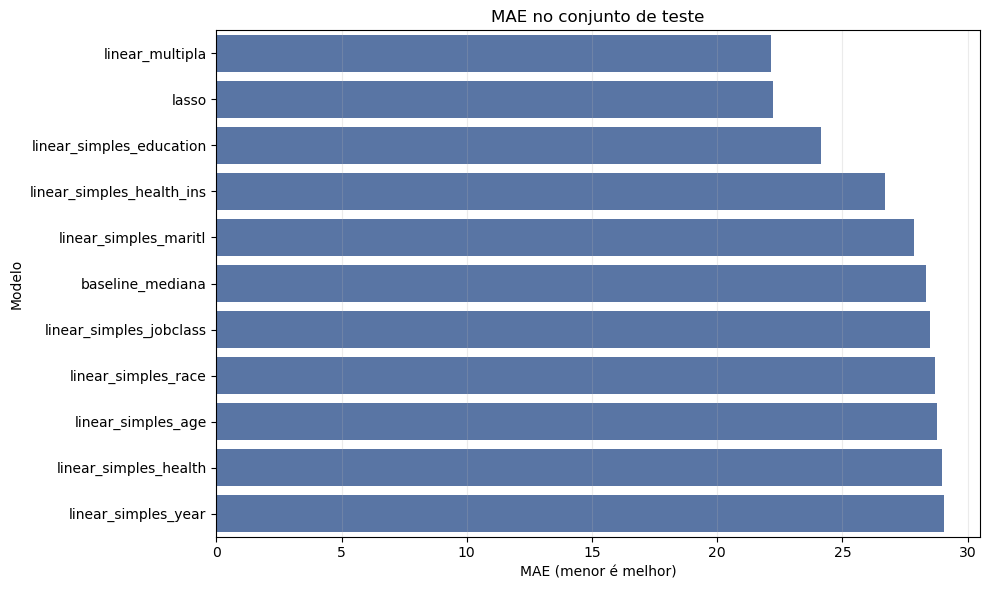

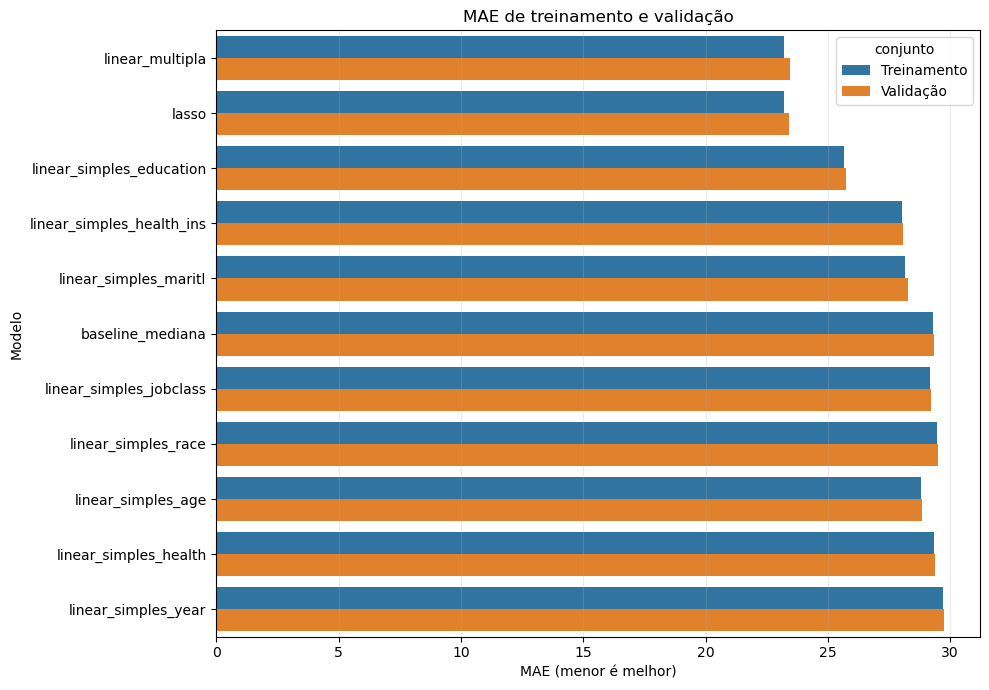

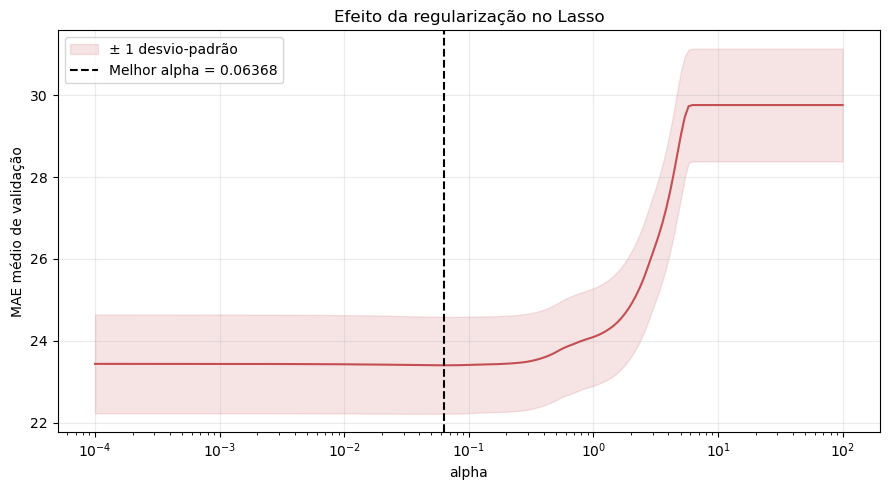

In [19]:
fig_comparacao, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=resultados_df, x='test_mae', y='modelo', ax=ax, color='#4C72B0')
ax.set(title='MAE no conjunto de teste', xlabel='MAE (menor é melhor)', ylabel='Modelo')
ax.grid(axis='x', alpha=0.25)
fig_comparacao.tight_layout()
figures_dir = project_root / 'report' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
fig_comparacao.savefig(figures_dir / 'mae_teste_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

comparacao_cv_df = resultados_df.melt(
    id_vars='modelo',
    value_vars=['train_mae_mean', 'cv_mae_mean'],
    var_name='conjunto', value_name='mae'
)
comparacao_cv_df['conjunto'] = comparacao_cv_df['conjunto'].map({
    'train_mae_mean': 'Treinamento', 'cv_mae_mean': 'Validação'
})
fig_treino_validacao, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=comparacao_cv_df, x='mae', y='modelo', hue='conjunto', ax=ax)
ax.set(title='MAE de treinamento e validação', xlabel='MAE (menor é melhor)', ylabel='Modelo')
ax.grid(axis='x', alpha=0.25)
fig_treino_validacao.tight_layout()
fig_treino_validacao.savefig(figures_dir / 'mae_treino_validacao.png', dpi=150, bbox_inches='tight')
plt.show()

fig_alpha, ax = plt.subplots(figsize=(9, 5))
mae_lasso_medio = -cv_lasso_df['mean_test_score'].to_numpy()
mae_lasso_std = cv_lasso_df['std_test_score'].to_numpy()
ax.plot(alphas, mae_lasso_medio, color='#C44E52')
ax.fill_between(
    alphas, mae_lasso_medio - mae_lasso_std, mae_lasso_medio + mae_lasso_std,
    color='#C44E52', alpha=0.15, label='± 1 desvio-padrão'
)
ax.axvline(melhor_alpha, color='black', linestyle='--', label=f'Melhor alpha = {melhor_alpha:.4g}')
ax.set_xscale('log')
ax.set(title='Efeito da regularização no Lasso', xlabel='alpha', ylabel='MAE médio de validação')
ax.grid(alpha=0.25)
ax.legend()
fig_alpha.tight_layout()
fig_alpha.savefig(figures_dir / 'alpha_vs_mae.png', dpi=150, bbox_inches='tight')
plt.show()

with mlflow.start_run(run_name='resumo_resultados'):
    mlflow.set_tags({
        'etapa': 'resumo_final',
        'dataset': 'data/wage.csv',
        'target': 'wage',
        'protocolo_validacao': 'RepeatedKFold',
    })
    mlflow.log_params({
        'n_splits': N_SPLITS,
        'n_repeats': N_REPEATS,
        'candidate_configurations': 209,
        'candidate_fits': 209 * N_SPLITS * N_REPEATS,
    })
    mlflow.log_table(resultados_df, 'resultados_modelos.json')
    mlflow.log_table(cenarios_df, 'cenarios_experimentais.json')
    mlflow.log_figure(fig_comparacao, 'mae_teste_modelos.png')
    mlflow.log_figure(fig_treino_validacao, 'mae_treino_validacao.png')
    mlflow.log_figure(fig_alpha, 'alpha_vs_mae.png')
    mlflow.log_dict({
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'scikit_learn': sklearn.__version__,
        'mlflow': mlflow.__version__,
        'random_state': RANDOM_STATE,
        'dataset': 'data/wage.csv',
        'pre_processamento': 'MinMax para variáveis numéricas e one-hot para categóricas',
    }, 'ambiente_e_proveniencia.json')
    mlflow.log_artifact(str(project_root / 'requirements.txt'), artifact_path='reprodutibilidade')
    mlflow.log_metrics({
        'best_test_mae': float(melhor_resultado['test_mae']),
        'baseline_test_mae': float(resultados_df.loc[resultados_df['modelo'] == 'baseline_mediana', 'test_mae'].iloc[0]),
    })

### Coeficientes selecionados pelo Lasso

In [20]:
coeficientes_lasso = (
    pd.DataFrame({
        'variavel': X.columns,
        'coeficiente': busca_lasso.best_estimator_.coef_,
    })
    .assign(magnitude=lambda tabela: tabela['coeficiente'].abs())
    .sort_values('magnitude', ascending=False)
)
display(coeficientes_lasso)
print(f'Coeficientes diferentes de zero: {(~np.isclose(coeficientes_lasso["coeficiente"], 0)).sum()} de {len(coeficientes_lasso)}')

,variavel,coeficiente,magnitude
12,education_5. Advanced Degree,48.571420,48.571420
11,education_4. College Grad,27.646032,27.646032
1,age,20.221759,20.221759
15,health_ins_2. No,-17.242592,17.242592
2,maritl_2. Married,15.488756,15.488756
10,education_3. Some College,13.394689,13.394689
14,health_2. >=Very Good,6.919590,6.919590
0,year,6.623044,6.623044
5,maritl_5. Separated,5.801553,5.801553
6,race_2. Black,-5.264152,5.264152


Coeficientes diferentes de zero: 15 de 16
